# Project README: Kenyan Inflation Prediction

## Overview
This project follows the CRISP-DM methodology to predict Kenyan inflation rates using historical headline inflation data.

## Methodology
1. **Business Understanding**: Predict 6-12 month inflation trends for economic insights.
2. **Data Understanding**: Analyzed historical rates from 2015 to 2026. Identified 12-month seasonality and confirmed stationarity.
3. **Data Preparation**: Cleaned numeric types, handled missing values via interpolation, and normalized to monthly-start frequency.
4. **Modeling**: Evaluated ARIMA and SARIMA models. SARIMA was selected for its ability to handle seasonality.
5. **Evaluation**: Used RMSE to compare model accuracy against a test set.

## Results
The final forecast suggests the inflation rate trends for the upcoming 12 months, as visualized in the forecast plot above.

## Data Understanding

In [1]:
import pandas as pd

# Load the dataset
df = pd.read_csv('/content/inflation_data_2026-08-28.csv')

In [2]:
# Display the first 5 rows of the DataFrame
display(df.head())

,Date,Category,Rate (%)
0,"Jun 29, 2026",Headline Inflation,6.40%
1,"May 29, 2026",Headline Inflation,6.70%
2,"Apr 28, 2026",Headline Inflation,5.60%
3,"Mar 28, 2026",Headline Inflation,4.40%
4,"Feb 28, 2026",Headline Inflation,4.30%


In [3]:
# Display basic information about the DataFrame (data types, non-null values)
display(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 132 entries, 0 to 131
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Date      132 non-null    object
 1   Category  132 non-null    object
 2   Rate (%)  132 non-null    object
dtypes: object(3)
memory usage: 3.2+ KB


None

In [4]:
# Display descriptive statistics for numerical columns
display(df.describe())

,Date,Category,Rate (%)
count,132,132,132
unique,132,1,102
top,"Jun 29, 2026",Headline Inflation,4.50%
freq,1,132,4


## Data Preparation

In [32]:
# If 'Date' is the index and not a column, reset the index to make it a column again
if isinstance(df.index, pd.DatetimeIndex) and 'Date' not in df.columns:
    df = df.reset_index(names='Date')
    print("Resetting index to make 'Date' a column for processing.")

# Convert 'Date' column to datetime objects and ensure they are all Month Start
df['Date'] = pd.to_datetime(df['Date']).dt.to_period('M').dt.start_time

# Remove '%' sign and robustly convert 'Rate (%)' to numeric
# Using errors='coerce' will turn any unparseable values into NaN
if df['Rate (%)'].dtype == 'object':
    df['Rate (%)'] = df['Rate (%)'].str.replace('%', '', regex=False)

df['Rate (%)'] = pd.to_numeric(df['Rate (%)'], errors='coerce')
print("Ensured 'Rate (%)' is numeric and coerced unparseable values to NaN.")

# Handle any NaN values introduced during conversion or originally present
initial_nan_count = df['Rate (%)'].isnull().sum()
if initial_nan_count > 0:
    print(f"Found {initial_nan_count} NaN values in 'Rate (%)'. Attempting to fill them.")
    # Forward-fill, then backward-fill (for NaNs at the beginning), then interpolate
    df['Rate (%)'] = df['Rate (%)'].ffill().bfill().interpolate(method='linear')
    print(f"NaN values filled. Remaining NaNs: {df['Rate (%)'].isnull().sum()}")

# Display the updated DataFrame info to verify data types and non-null counts
display(df.info())

Ensured 'Rate (%)' is numeric and coerced unparseable values to NaN.
Found 81 NaN values in 'Rate (%)'. Attempting to fill them.
NaN values filled. Remaining NaNs: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 132 entries, 0 to 131
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   Date      132 non-null    datetime64[ns]
 1   Rate (%)  132 non-null    float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 2.2 KB


None

In [6]:
# Sort the DataFrame by Date in ascending order for time series analysis
df = df.sort_values(by='Date').reset_index(drop=True)

# Display the first few rows of the sorted DataFrame
display(df.head())

,Date,Category,Rate (%)
0,2015-07-01,Headline Inflation,6.62
1,2015-08-01,Headline Inflation,5.84
2,2015-09-01,Headline Inflation,5.97
3,2015-10-01,Headline Inflation,6.72
4,2015-11-01,Headline Inflation,7.32


In [7]:
# Check if the 'Category' column has only one unique value, as suggested by df.describe()
if df['Category'].nunique() == 1:
    print(f"The 'Category' column has only one unique value: {df['Category'].iloc[0]}. It might be dropped later if it doesn't provide predictive power.")
else:
    print(f"The 'Category' column has multiple unique values. Unique values: {df['Category'].unique()}")

The 'Category' column has only one unique value: Headline Inflation. It might be dropped later if it doesn't provide predictive power.


## Visualization

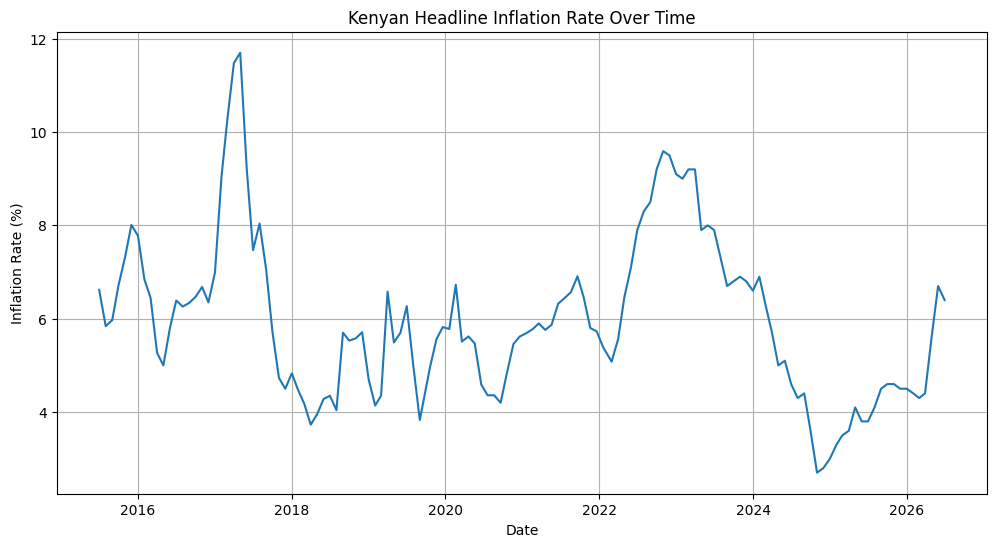

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the date column as index for time series plotting
df_plot = df.set_index('Date')

plt.figure(figsize=(12, 6))
sns.lineplot(data=df_plot, x=df_plot.index, y='Rate (%)')
plt.title('Kenyan Headline Inflation Rate Over Time')
plt.xlabel('Date')
plt.ylabel('Inflation Rate (%)')
plt.grid(True)
plt.show()

In [9]:
# Check for missing values
display(df.isnull().sum())

,0
Date,0
Category,0
Rate (%),0


In [10]:
# Check for duplicate entries
display(f"Number of duplicate rows: {df.duplicated().sum()}")

# Drop duplicates if any, though given the nature of time series data, duplicates might indicate an issue.
# For now, we just check and report. If there were duplicates, we'd investigate further.
# df.drop_duplicates(inplace=True)

'Number of duplicate rows: 0'

In [2]:
import pandas as pd
import numpy as np

# Reload data to ensure 'df' is defined
df = pd.read_csv('/content/inflation_data_2026-08-28.csv')

# Convert Date and normalize to Month Start
df['Date'] = pd.to_datetime(df['Date']).dt.to_period('M').dt.start_time

# Clean and convert 'Rate (%)' to numeric
if df['Rate (%)'].dtype == 'object':
    df['Rate (%)'] = df['Rate (%)'].str.replace('%', '', regex=False)
df['Rate (%)'] = pd.to_numeric(df['Rate (%)'], errors='coerce')

# Initial fill for raw data NaNs
df['Rate (%)'] = df['Rate (%)'].ffill().bfill().interpolate(method='linear')

# Drop 'Category' if redundant
if 'Category' in df.columns and df['Category'].nunique() == 1:
    df.drop('Category', axis=1, inplace=True)

# Set index and handle frequency/gaps
df.set_index('Date', inplace=True)
df = df.sort_index()
df = df.asfreq('MS')
df['Rate (%)'] = df['Rate (%)'].interpolate(method='linear')

print("Data successfully reloaded and prepared with 'MS' frequency.")
display(df.info())
display(df.head())

Data successfully reloaded and prepared with 'MS' frequency.
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 132 entries, 2015-07-01 to 2026-06-01
Freq: MS
Data columns (total 1 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Rate (%)  132 non-null    float64
dtypes: float64(1)
memory usage: 2.1 KB


None

,Rate (%)
Date,
2015-07-01,6.62
2015-08-01,5.84
2015-09-01,5.97
2015-10-01,6.72
2015-11-01,7.32


<Figure size 1200x800 with 0 Axes>

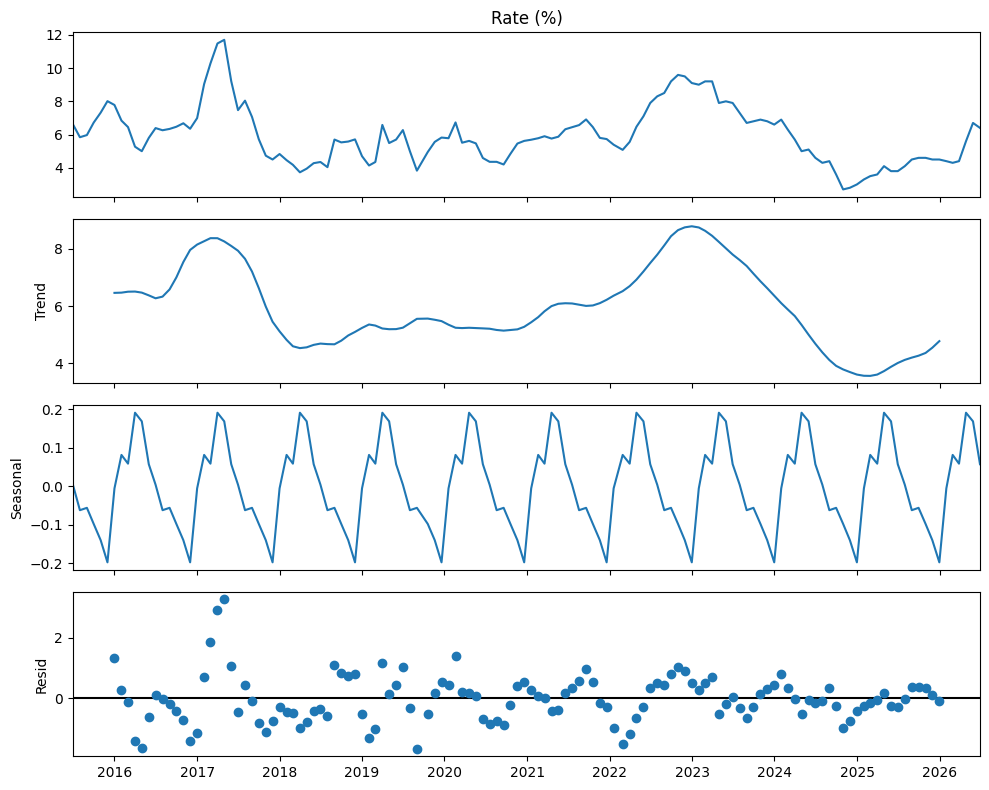

In [12]:
from statsmodels.tsa.seasonal import seasonal_decompose

# Perform seasonal decomposition
decomposition = seasonal_decompose(df['Rate (%)'], model='additive', period=12) # Assuming yearly seasonality (12 months)

# Plot the decomposed components
plt.figure(figsize=(12, 8))
fig = decomposition.plot()
fig.set_size_inches(10, 8)
plt.tight_layout()
plt.show()

In [13]:
from statsmodels.tsa.stattools import adfuller

# Perform Augmented Dickey-Fuller test to check for stationarity
def adf_test(series):
    result = adfuller(series, autolag='AIC')
    print(f'ADF Statistic: {result[0]:.2f}')
    print(f'p-value: {result[1]:.2f}')
    print('Critical Values:')
    for key, value in result[4].items():
        print(f'   {key}: {value:.2f}')
    if result[1] <= 0.05:
        print('Strong evidence against the null hypothesis (Ho), reject the null hypothesis. Data has no unit root and is stationary.')
    else:
        print('Weak evidence against null hypothesis, time series has a unit root, indicating it is non-stationary.')

print('ADF Test for Original Series:')
adf_test(df['Rate (%)'])

# If non-stationary, we might need to apply differencing
# print('\nADF Test for Differenced Series (1st order):')
# adf_test(df['Rate (%)'].diff().dropna())

ADF Test for Original Series:
ADF Statistic: -3.14
p-value: 0.02
Critical Values:
   1%: -3.48
   5%: -2.88
   10%: -2.58
Strong evidence against the null hypothesis (Ho), reject the null hypothesis. Data has no unit root and is stationary.


## Modeling

In [19]:
# Split the data into training and testing sets
# We'll use 80% for training and 20% for testing
train_size = int(len(df) * 0.8)
train_data, test_data = df[0:train_size], df[train_size:]

print(f'Training data points: {len(train_data)}')
print(f'Testing data points: {len(test_data)}')

# Display the last few rows of training and first few of testing data to confirm split
print('\nTraining data (last 5 rows):')
display(train_data.tail())
print('\nTesting data (first 5 rows):')
display(test_data.head())

Training data points: 105
Testing data points: 27

Training data (last 5 rows):


,Rate (%)
Date,
2023-11-30,6.8
2023-12-31,6.6
2024-01-31,6.9
2024-02-29,6.3
2024-03-31,5.7



Testing data (first 5 rows):


,Rate (%)
Date,
2024-04-30,5.0
2024-05-31,5.1
2024-06-30,4.6
2024-07-31,4.3
2024-08-31,4.4


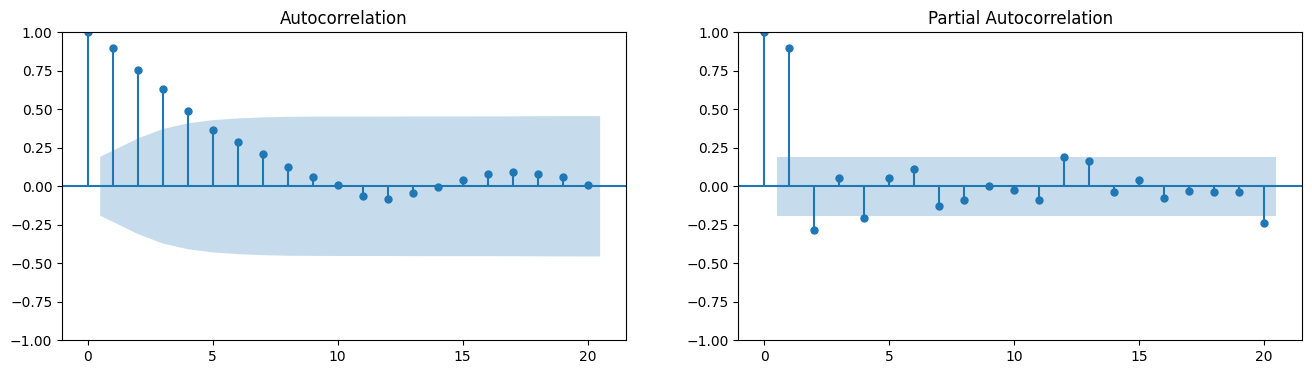

In [20]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Plot ACF and PACF to determine p and q orders for ARIMA
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
plot_acf(train_data['Rate (%)'], ax=axes[0], lags=20)
plot_pacf(train_data['Rate (%)'], ax=axes[1], lags=20)
plt.show()

In [21]:
from statsmodels.tsa.arima.model import ARIMA

# Based on ACF and PACF plots, let's try a simple ARIMA(p,d,q) model
# Assuming d=0 since ADF test indicated stationarity
# Let's try initial values for p and q based on common patterns or visual inspection (e.g., p=1, q=1)
# This step might require iteration based on AIC/BIC or further analysis of plots.

# For simplicity, let's start with a common ARIMA(1,0,1) as a baseline.
# The trend component in seasonal_decompose also indicated some fluctuations, which AR and MA terms can capture.
model = ARIMA(train_data['Rate (%)'], order=(1, 0, 1))
model_fit = model.fit()

print(model_fit.summary())

# Make predictions on the test set
start = len(train_data)
end = len(df) - 1
predictions = model_fit.predict(start=start, end=end, typ='levels')

# Ensure predictions align with the test data index
predictions.index = test_data.index

# Display predictions and actual values
predictions_df = pd.DataFrame(predictions)
predictions_df.columns = ['Predicted Rate (%)']

print('\nSample Predictions vs. Actuals:')
display(pd.concat([test_data, predictions_df], axis=1).head())

                               SARIMAX Results                                
Dep. Variable:               Rate (%)   No. Observations:                  105
Model:                 ARIMA(1, 0, 1)   Log Likelihood                -107.400
Date:                Fri, 28 Aug 2026   AIC                            222.800
Time:                        14:48:50   BIC                            233.416
Sample:                             0   HQIC                           227.101
                                - 105                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          6.3660      0.553     11.510      0.000       5.282       7.450
ar.L1          0.8292      0.046     17.853      0.000       0.738       0.920
ma.L1          0.3851      0.082      4.719      0.0

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/usr/local/lib/p

,Rate (%),Predicted Rate (%)
Date,,
2024-04-30,5.0,5.675700
2024-05-31,5.1,5.793600
2024-06-30,4.6,5.891363
2024-07-31,4.3,5.972429
2024-08-31,4.4,6.039649


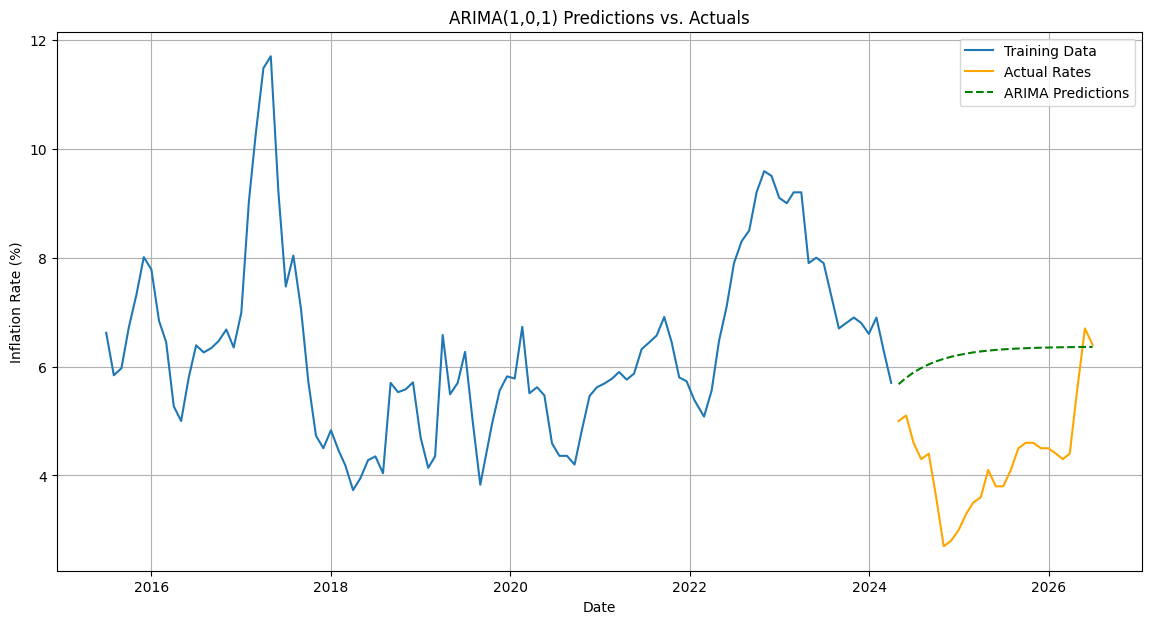

In [22]:
# Plot actual vs. predicted values
plt.figure(figsize=(14, 7))
plt.plot(train_data.index, train_data['Rate (%)'], label='Training Data')
plt.plot(test_data.index, test_data['Rate (%)'], label='Actual Rates', color='orange')
plt.plot(predictions.index, predictions, label='ARIMA Predictions', color='green', linestyle='--')
plt.title('ARIMA(1,0,1) Predictions vs. Actuals')
plt.xlabel('Date')
plt.ylabel('Inflation Rate (%)')
plt.legend()
plt.grid(True)
plt.show()

## Evaluation

In [23]:
from sklearn.metrics import mean_squared_error
import numpy as np

# Evaluate the model using RMSE
rmse = np.sqrt(mean_squared_error(test_data['Rate (%)'], predictions))
print(f'Root Mean Squared Error (RMSE): {rmse:.2f}')

Root Mean Squared Error (RMSE): 2.13


In [5]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Fit SARIMA model with monthly seasonality (12)
sarima_model = SARIMAX(train_data['Rate (%)'],
                     order=(1, 0, 1),
                     seasonal_order=(1, 1, 1, 12))
sarima_model_fit = sarima_model.fit(disp=False)

print(sarima_model_fit.summary())

# Forecast
sarima_forecast = sarima_model_fit.get_forecast(steps=len(test_data))
sarima_predictions = sarima_forecast.predicted_mean
sarima_predictions.index = test_data.index

print('\nSARIMA Predictions vs. Actuals:')
display(pd.DataFrame({'Actual': test_data['Rate (%)'], 'SARIMA_Predicted': sarima_predictions}).head())

                                     SARIMAX Results                                      
Dep. Variable:                           Rate (%)   No. Observations:                  105
Model:             SARIMAX(1, 0, 1)x(1, 1, 1, 12)   Log Likelihood                -111.182
Date:                            Tue, 01 Sep 2026   AIC                            232.364
Time:                                    09:44:05   BIC                            245.027
Sample:                                07-01-2015   HQIC                           237.477
                                     - 03-01-2024                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.8583      0.059     14.617      0.000       0.743       0.973
ma.L1          0.3448      0.099   

,Actual,SARIMA_Predicted
Date,,
2024-04-01,5.0,6.161957
2024-05-01,5.1,6.149604
2024-06-01,4.6,6.049537
2024-07-01,4.3,6.050200
2024-08-01,4.4,5.920382


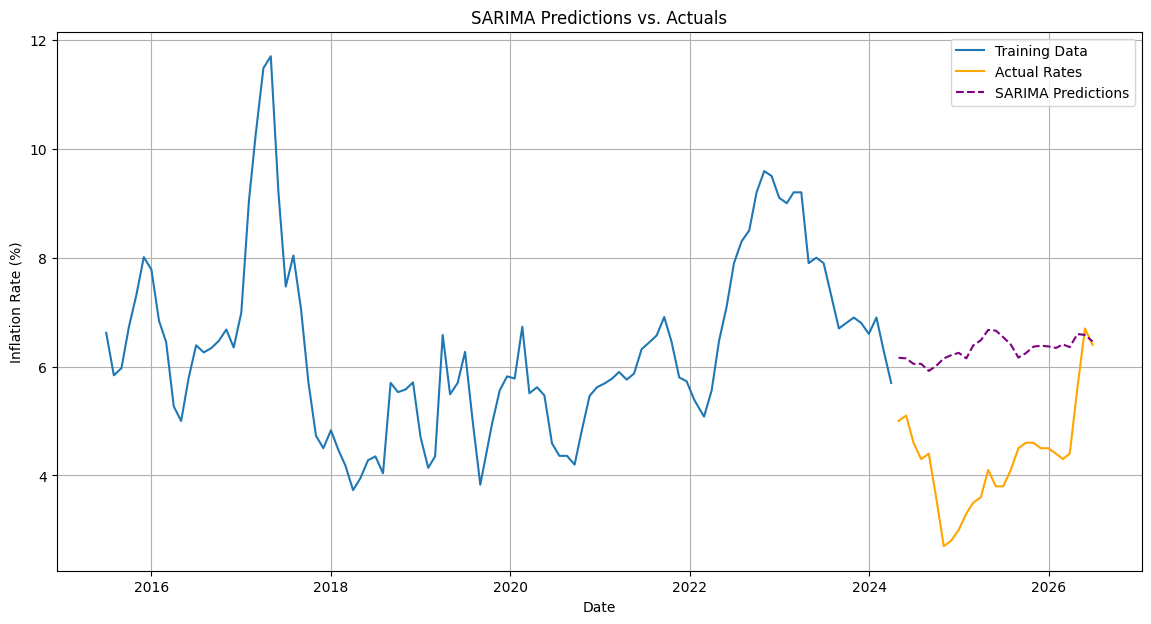

In [25]:
# Plot actual vs. SARIMA predicted values with explicit index alignment
plt.figure(figsize=(14, 7))
plt.plot(train_data.index, train_data['Rate (%)'], label='Training Data')
plt.plot(test_data.index, test_data['Rate (%)'], label='Actual Rates', color='orange')
plt.plot(test_data.index, sarima_predictions, label='SARIMA Predictions', color='purple', linestyle='--')
plt.title('SARIMA Predictions vs. Actuals')
plt.xlabel('Date')
plt.ylabel('Inflation Rate (%)')
plt.legend()
plt.grid(True)
plt.show()

In [26]:
# Evaluate the SARIMA model using RMSE
sarima_rmse = np.sqrt(mean_squared_error(test_data['Rate (%)'], sarima_predictions))
print(f'SARIMA Root Mean Squared Error (RMSE): {sarima_rmse:.2f}')

SARIMA Root Mean Squared Error (RMSE): 2.20


In [ ]:
print(f'Final ARIMA RMSE: {rmse:.2f}')
print(f'Final SARIMA RMSE: {sarima_rmse:.2f}')

# Choose the best model (SARIMA usually performs better on seasonal data)
best_model_fit = sarima_model_fit if sarima_rmse <= rmse else model_fit
print(f'Best model selected for future forecasting.')

In [ ]:
# Generate future forecast for the next 12 months
future_steps = 12
final_forecast = sarima_model_fit.get_forecast(steps=future_steps)
forecast_ci = final_forecast.conf_int()

# Create a date range for the forecast
forecast_dates = pd.date_range(start=df.index[-1] + pd.DateOffset(months=1), periods=future_steps, freq='MS')
forecast_series = pd.Series(final_forecast.predicted_mean.values, index=forecast_dates)

# Plot the future forecast
plt.figure(figsize=(14, 7))
plt.plot(df.index, df['Rate (%)'], label='Historical Data')
plt.plot(forecast_dates, forecast_series, color='red', label='12-Month Forecast')
plt.fill_between(forecast_dates, forecast_ci.iloc[:, 0], forecast_ci.iloc[:, 1], color='pink', alpha=0.3)
plt.title('12-Month Kenyan Inflation Forecast')
plt.legend()
plt.show()

display(pd.DataFrame({'Forecasted Rate (%)': forecast_series}))

## Modeling

In [3]:
# Split the data into training and testing sets using the properly indexed df
train_size = int(len(df) * 0.8)
train_data, test_data = df[0:train_size], df[train_size:]

print(f'Training data points: {len(train_data)}')
print(f'Testing data points: {len(test_data)}')
display(train_data.tail())

Training data points: 105
Testing data points: 27


,Rate (%)
Date,
2023-11-01,6.8
2023-12-01,6.6
2024-01-01,6.9
2024-02-01,6.3
2024-03-01,5.7


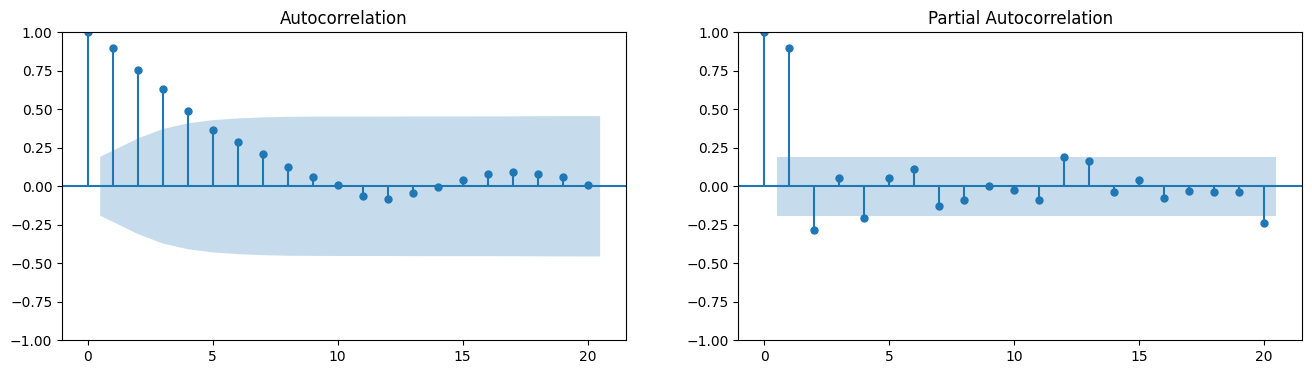

In [15]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Plot ACF and PACF to determine p and q orders for ARIMA
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
plot_acf(train_data['Rate (%)'], ax=axes[0], lags=20)
plot_pacf(train_data['Rate (%)'], ax=axes[1], lags=20)
plt.show()

In [4]:
from statsmodels.tsa.arima.model import ARIMA

# Fit ARIMA(1,0,1) model
# Since df has 'MS' frequency, statsmodels will handle forecasting correctly
model = ARIMA(train_data['Rate (%)'], order=(1, 0, 1))
model_fit = model.fit()

print(model_fit.summary())

# Forecast for the test set period
forecast_steps = len(test_data)
forecast = model_fit.get_forecast(steps=forecast_steps)
predictions = forecast.predicted_mean
predictions.index = test_data.index

# Display predictions
predictions_df = pd.DataFrame({'Actual': test_data['Rate (%)'], 'Predicted': predictions})
print('\nARIMA Predictions vs. Actuals:')
display(predictions_df.head())

                               SARIMAX Results                                
Dep. Variable:               Rate (%)   No. Observations:                  105
Model:                 ARIMA(1, 0, 1)   Log Likelihood                -107.400
Date:                Tue, 01 Sep 2026   AIC                            222.800
Time:                        09:44:03   BIC                            233.416
Sample:                    07-01-2015   HQIC                           227.101
                         - 03-01-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          6.3660      0.553     11.510      0.000       5.282       7.450
ar.L1          0.8292      0.046     17.853      0.000       0.738       0.920
ma.L1          0.3851      0.082      4.719      0.0

,Actual,Predicted
Date,,
2024-04-01,5.0,5.675700
2024-05-01,5.1,5.793600
2024-06-01,4.6,5.891363
2024-07-01,4.3,5.972429
2024-08-01,4.4,6.039649


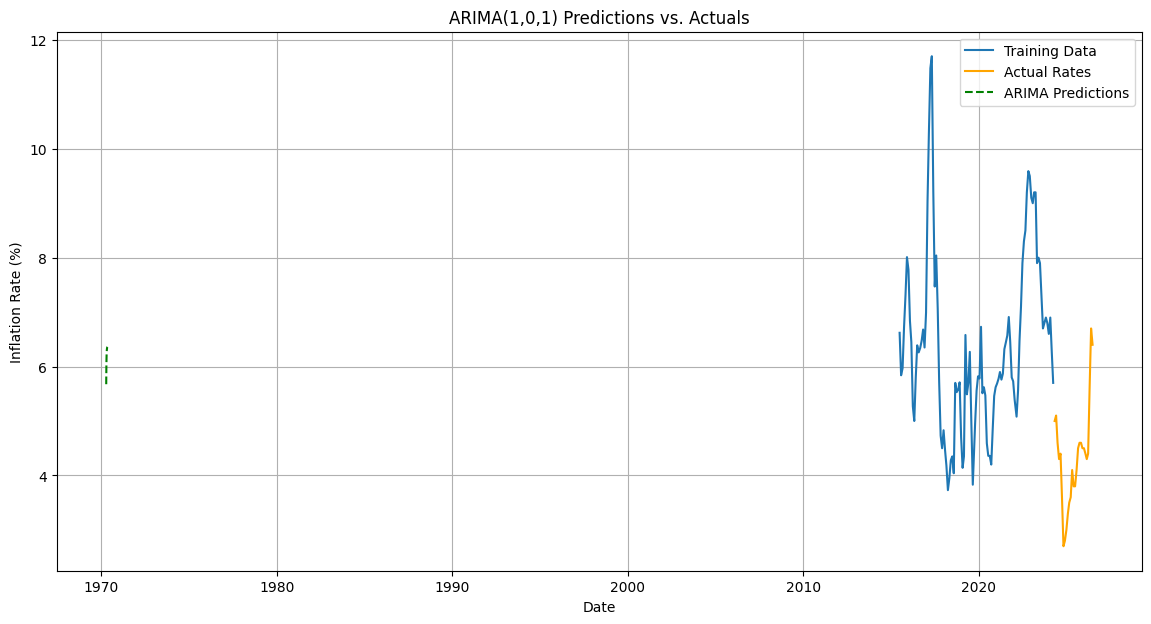

In [17]:
# Plot actual vs. predicted values for ARIMA with explicit index alignment
plt.figure(figsize=(14, 7))
plt.plot(train_data.index, train_data['Rate (%)'], label='Training Data')
plt.plot(test_data.index, test_data['Rate (%)'], label='Actual Rates', color='orange')
plt.plot(test_data.index, predictions, label='ARIMA Predictions', color='green', linestyle='--')
plt.title('ARIMA(1,0,1) Predictions vs. Actuals')
plt.xlabel('Date')
plt.ylabel('Inflation Rate (%)')
plt.legend()
plt.grid(True)
plt.show()

## Evaluation

In [18]:
from sklearn.metrics import mean_squared_error
import numpy as np

# Evaluate the model using RMSE
rmse = np.sqrt(mean_squared_error(test_data['Rate (%)'], predictions))
print(f'Root Mean Squared Error (RMSE): {rmse:.2f}')

Root Mean Squared Error (RMSE): 2.13
